In [3]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer
import matplotlib.pyplot as plt
import seaborn as sns


In [5]:
destinations_df=pd.read_csv("Expanded_Destinations.csv")
reviews_df=pd.read_csv("Final_Updated_Expanded_Reviews.csv")
userhistory_df=pd.read_csv("Final_Updated_Expanded_UserHistory.csv")
users_df=pd.read_csv("Final_Updated_Expanded_Users.csv")

In [6]:
destinations_df.head()

,DestinationID,Name,State,Type,Popularity,BestTimeToVisit
0,1,Taj Mahal,Uttar Pradesh,Historical,8.691906,Nov-Feb
1,2,Goa Beaches,Goa,Beach,8.605032,Nov-Mar
2,3,Jaipur City,Rajasthan,City,9.225372,Oct-Mar
3,4,Kerala Backwaters,Kerala,Nature,7.977386,Sep-Mar
4,5,Leh Ladakh,Jammu and Kashmir,Adventure,8.399822,Apr-Jun


In [7]:
reviews_df.head()

,ReviewID,DestinationID,UserID,Rating,ReviewText
0,1,178,327,2,Incredible monument!
1,2,411,783,1,Loved the beaches!
2,3,927,12,2,A historical wonder
3,4,358,959,3,Incredible monument!
4,5,989,353,2,Loved the beaches!


In [8]:
userhistory_df.head()

,HistoryID,UserID,DestinationID,VisitDate,ExperienceRating
0,1,525,760,2024-01-01,3
1,2,184,532,2024-02-15,5
2,3,897,786,2024-03-20,2
3,4,470,660,2024-01-01,1
4,5,989,389,2024-02-15,4


In [9]:
users_df.head()


,UserID,Name,Email,Preferences,Gender,NumberOfAdults,NumberOfChildren
0,1,Kavya,kavya@example.com,"Beaches, Historical",Female,1,0
1,2,Rohan,rohan@example.com,"Nature, Adventure",Male,2,2
2,3,Kavya,kavya@example.com,"City, Historical",Female,2,0
3,4,Anika,anika@example.com,"Beaches, Historical",Female,1,0
4,5,Tanvi,tanvi@example.com,"Nature, Adventure",Female,2,2


In [11]:
reviews_destinations = pd.merge(reviews_df, destinations_df, on='DestinationID', how='inner')
reviews_destinations

,ReviewID,DestinationID,UserID,Rating,ReviewText,Name,State,Type,Popularity,BestTimeToVisit
0,1,178,327,2,Incredible monument!,Jaipur City,Rajasthan,City,8.544352,Oct-Mar
1,2,411,783,1,Loved the beaches!,Taj Mahal,Uttar Pradesh,Historical,8.284127,Nov-Feb
2,3,927,12,2,A historical wonder,Goa Beaches,Goa,Beach,7.741214,Nov-Mar
3,4,358,959,3,Incredible monument!,Jaipur City,Rajasthan,City,7.738761,Oct-Mar
4,5,989,353,2,Loved the beaches!,Kerala Backwaters,Kerala,Nature,8.208088,Sep-Mar
...,...,...,...,...,...,...,...,...,...,...
994,995,231,346,5,Loved the beaches!,Taj Mahal,Uttar Pradesh,Historical,7.788256,Nov-Feb
995,996,140,140,3,A historical wonder,Leh Ladakh,Jammu and Kashmir,Adventure,8.907808,Apr-Jun
996,997,823,858,5,Incredible monument!,Jaipur City,Rajasthan,City,8.501225,Oct-Mar
997,998,279,839,2,Loved the beaches!,Kerala Backwaters,Kerala,Nature,7.841207,Sep-Mar


In [12]:
reviews_destinations_userhistory = pd.merge(userhistory_df,users_df,on='UserID',how='inner')


In [13]:
reviews_destinations_userhistory 


,HistoryID,UserID,DestinationID,VisitDate,ExperienceRating,Name,Email,Preferences,Gender,NumberOfAdults,NumberOfChildren
0,1,525,760,2024-01-01,3,Saanvi,saanvi@example.com,"City, Historical",Female,2,2
1,2,184,532,2024-02-15,5,Ishaan,ishaan@example.com,"Beaches, Historical",Male,1,2
2,3,897,786,2024-03-20,2,Pooja,pooja@example.com,"City, Historical",Female,1,2
3,4,470,660,2024-01-01,1,Arjun,arjun@example.com,"Nature, Adventure",Male,2,1
4,5,989,389,2024-02-15,4,Ritvik,ritvik@example.com,"Nature, Adventure",Male,2,1
...,...,...,...,...,...,...,...,...,...,...,...
994,995,129,240,2024-02-15,3,Aarav,aarav@example.com,"City, Historical",Male,2,1
995,996,634,359,2024-03-20,3,Dhruv,dhruv@example.com,"Beaches, Historical",Male,2,2
996,997,831,78,2024-01-01,1,Pooja,pooja@example.com,"City, Historical",Female,2,2
997,998,959,660,2024-02-15,4,Ritvik,ritvik@example.com,"Nature, Adventure",Male,1,1


In [14]:
df=pd.merge(reviews_destinations,reviews_destinations_userhistory,on='UserID',how='inner')

In [15]:
df

,ReviewID,DestinationID_x,UserID,Rating,ReviewText,Name_x,State,Type,Popularity,BestTimeToVisit,HistoryID,DestinationID_y,VisitDate,ExperienceRating,Name_y,Email,Preferences,Gender,NumberOfAdults,NumberOfChildren
0,1,178,327,2,Incredible monument!,Jaipur City,Rajasthan,City,8.544352,Oct-Mar,79,175,2024-01-01,3,Pooja,pooja@example.com,"City, Historical",Female,1,1
1,2,411,783,1,Loved the beaches!,Taj Mahal,Uttar Pradesh,Historical,8.284127,Nov-Feb,834,894,2024-03-20,2,Karan,karan@example.com,"City, Historical",Male,1,1
2,4,358,959,3,Incredible monument!,Jaipur City,Rajasthan,City,7.738761,Oct-Mar,998,660,2024-02-15,4,Ritvik,ritvik@example.com,"Nature, Adventure",Male,1,1
3,5,989,353,2,Loved the beaches!,Kerala Backwaters,Kerala,Nature,8.208088,Sep-Mar,202,894,2024-01-01,5,Isha,isha@example.com,"Nature, Adventure",Female,2,0
4,6,473,408,4,A historical wonder,Jaipur City,Rajasthan,City,8.138558,Oct-Mar,331,403,2024-01-01,2,Ishaan,ishaan@example.com,"City, Historical",Male,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
988,991,701,850,3,Incredible monument!,Taj Mahal,Uttar Pradesh,Historical,8.814029,Nov-Feb,138,131,2024-03-20,1,Hitesh,hitesh@example.com,"Beaches, Historical",Male,2,0
989,991,701,850,3,Incredible monument!,Taj Mahal,Uttar Pradesh,Historical,8.814029,Nov-Feb,643,761,2024-01-01,4,Hitesh,hitesh@example.com,"Beaches, Historical",Male,2,0
990,995,231,346,5,Loved the beaches!,Taj Mahal,Uttar Pradesh,Historical,7.788256,Nov-Feb,454,113,2024-01-01,2,Hitesh,hitesh@example.com,"Beaches, Historical",Male,2,2
991,995,231,346,5,Loved the beaches!,Taj Mahal,Uttar Pradesh,Historical,7.788256,Nov-Feb,556,128,2024-01-01,4,Hitesh,hitesh@example.com,"Beaches, Historical",Male,2,2


In [19]:
df.duplicated().sum() #no duplicates

np.int64(0)

In [20]:
df.isnull().sum() 
#no missing values, heading forward with the visualization.

ReviewID            0
DestinationID_x     0
UserID              0
Rating              0
ReviewText          0
Name_x              0
State               0
Type                0
Popularity          0
BestTimeToVisit     0
HistoryID           0
DestinationID_y     0
VisitDate           0
ExperienceRating    0
Name_y              0
Email               0
Preferences         0
Gender              0
NumberOfAdults      0
NumberOfChildren    0
dtype: int64

C:\Users\dongare\AppData\Local\Temp\ipykernel_10152\1664715010.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Popularity',y='Name',data=destinations_df.sort_values('Popularity',ascending=False).head(10),palette='viridis')


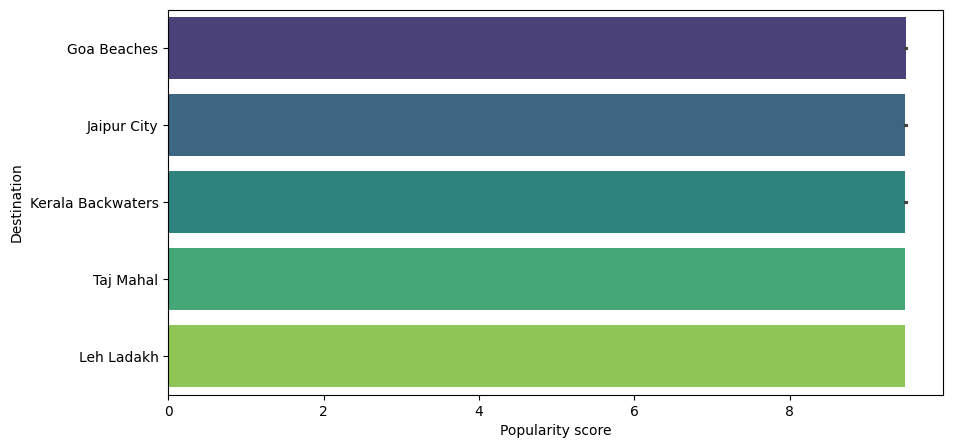

In [26]:
#1 destination popularity

plt.figure(figsize=(10,5))
sns.barplot(x='Popularity',y='Name',data=destinations_df.sort_values('Popularity',ascending=False).head(10),palette='viridis')
plt.xlabel("Popularity score")
plt.ylabel("Destination")
plt.show()

C:\Users\dongare\AppData\Local\Temp\ipykernel_10152\1708787096.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='Type',data=destinations_df,order=destinations_df['Type'].value_counts().index,palette='coolwarm')


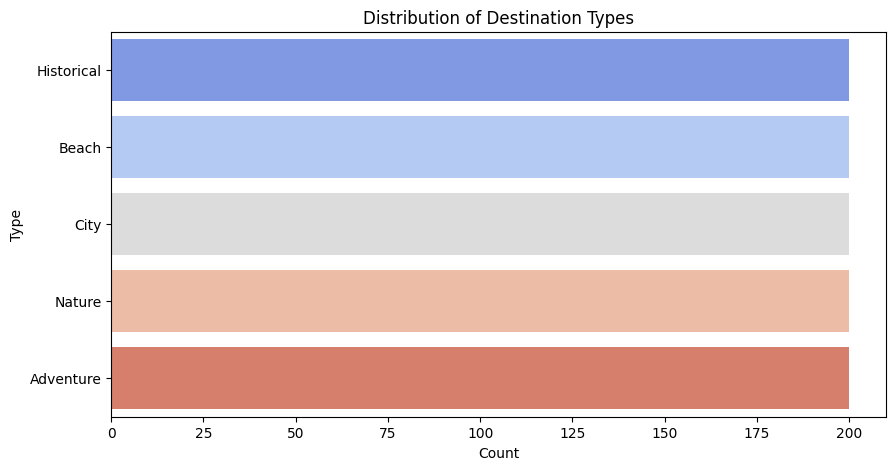

In [30]:
#1 destination Types distributions

plt.figure(figsize=(10,5))
sns.countplot(y='Type',data=destinations_df,order=destinations_df['Type'].value_counts().index,palette='coolwarm')
plt.title("Distribution of Destination Types")
plt.xlabel("Count")
plt.ylabel("Type")
plt.show()

C:\Users\dongare\AppData\Local\Temp\ipykernel_10152\1024496459.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='BestTimeToVisit',data=destinations_df,order=destinations_df['BestTimeToVisit'].value_counts().index,palette='viridis')


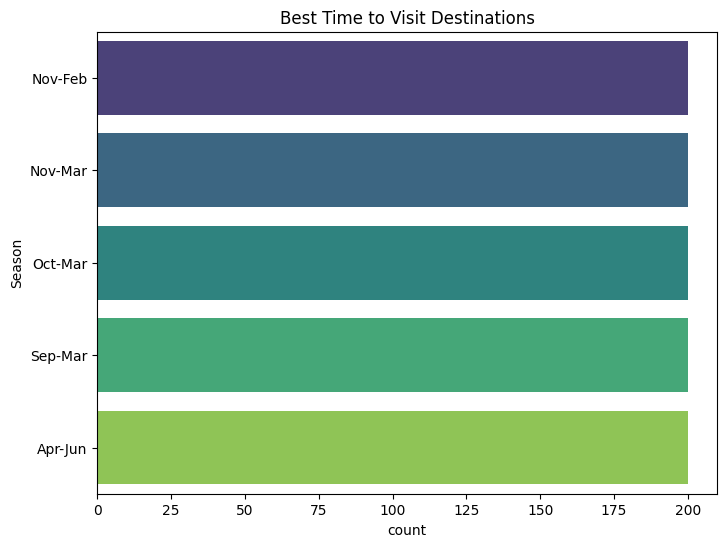

In [31]:
# Best time to visit destinations

plt.figure(figsize=(8,6))
sns.countplot(y='BestTimeToVisit',data=destinations_df,order=destinations_df['BestTimeToVisit'].value_counts().index,palette='viridis')
plt.title("Best Time to Visit Destinations")
plt.xlabel("count")
plt.ylabel("Season")
plt.show()

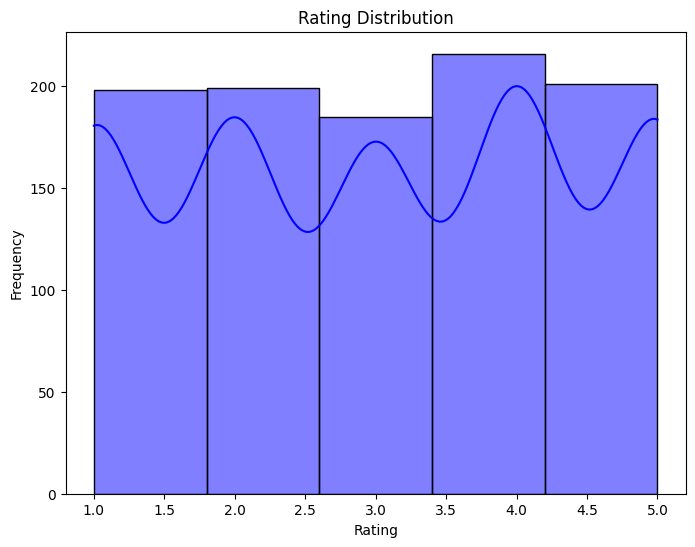

In [32]:
#4 Rating distribution

plt.figure(figsize=(8,6))
sns.histplot(reviews_df['Rating'],bins=5,kde=True,color='blue')
plt.title("Rating Distribution")
plt.xlabel("Rating")    
plt.ylabel("Frequency")
plt.show() 